In [ ]:

# STEP 1: CONNECT GOOGLE DRIVE AND FIND THE DATASET

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
import os

folder_path = "/content/drive/MyDrive/Infosys Project/archive/2020-05-01"

In [ ]:

# STEP 2: LOAD THE DATASET FROM THE FOUND PATH

import pandas as pd
import os

# Construct the file path directly using the defined folder_path
csv_path = os.path.join(folder_path, "ted_talks_en.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Could not find 'ted_talks_en.csv' at: {csv_path}. Please check your Google Drive path."
    )

# Load the dataset
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("File path:", csv_path)
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
File path: /content/drive/MyDrive/Infosys Project/archive/2020-05-01/ted_talks_en.csv
Dataset shape: (4005, 19)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [ ]:
# MODULE 5: STEP 1 — INSPECT RELATED TALKS

import pandas as pd
import numpy as np
import ast

# Check dataset information
print("Dataset Shape:", df.shape)

# Check required columns
print("\nRequired columns:")
print(df[["talk_id", "title", "related_talks"]].columns.tolist())

# Check data types
print("\nColumn Data Types:")
print(df[["talk_id", "related_talks"]].dtypes)

# Display first 10 related talk records
print("\nSample Related Talks:")

for i in range(10):
    print("\nTalk ID:", df.iloc[i]["talk_id"])
    print("Title:", df.iloc[i]["title"])
    print("Related Talks:", df.iloc[i]["related_talks"])

# Check missing values
print("\nMissing Related Talks:",
      df["related_talks"].isna().sum())

# Check unique talk IDs
print("\nUnique Talk IDs:",
      df["talk_id"].nunique())

Dataset Shape: (4005, 19)

Required columns:
['talk_id', 'title', 'related_talks']

Column Data Types:
talk_id           int64
related_talks    object
dtype: object

Sample Related Talks:

Talk ID: 1
Title: Averting the climate crisis
Related Talks: {243: 'New thinking on the climate crisis', 547: 'The business logic of sustainability', 2093: 'The state of the climate — and what we might do about it', 54715: 'How we can turn the tide on climate', 29968: 'The most important thing you can do to fight climate change: talk about it', 2339: "Climate change is happening. Here's how we adapt"}

Talk ID: 92
Title: The best stats you've ever seen
Related Talks: {2056: "Own your body's data", 2296: 'A visual history of human knowledge', 620: 'Let my dataset change your mindset', 2806: "Doesn't everyone deserve a chance at a good life?", 2560: 'How Africa can keep rising', 1418: "Let's put birth control back on the agenda"}

Talk ID: 7
Title: Simplicity sells
Related Talks: {1725: '10 top time-sa

In [ ]:
# MODULE 5: STEP 2 — PREPARE RELEVANT TALK IDs

import re
import ast

def parse_related_talks(value):

    if isinstance(value, (list, tuple, set)):
        parsed = list(value)

    elif isinstance(value, str) and value.strip():

        try:
            parsed = ast.literal_eval(value)

            if not isinstance(parsed, (list, tuple, set)):
                parsed = [parsed]

        except (ValueError, SyntaxError):
            parsed = re.findall(r'\d+', value)

    else:
        return []

    result = []

    for item in parsed:
        # Extract numeric ID from values such as "1234"
        match = re.search(r'\d+', str(item))

        if match:
            result.append(match.group())

    return list(dict.fromkeys(result))


# Create a clean copy of the dataset
evaluation_df = df[
    ["talk_id", "title", "related_talks"]
].copy()

evaluation_df["talk_id"] = (
    evaluation_df["talk_id"].astype(str).str.strip()
)

evaluation_df["relevant_ids"] = (
    evaluation_df["related_talks"].apply(parse_related_talks)
)

# Create valid talk ID set
valid_talk_ids = set(evaluation_df["talk_id"])

# Keep only related IDs that exist in the dataset
evaluation_df["relevant_ids"] = evaluation_df[
    "relevant_ids"
].apply(lambda ids: [x for x in ids if x in valid_talk_ids])

# Check matching information
total_references = sum(
    len(ids) for ids in evaluation_df["relevant_ids"]
)

print("Total talks:", len(evaluation_df))
print("Talks with valid related talks:",
      (evaluation_df["relevant_ids"].str.len() > 0).sum())
print("Valid related-talk references:", total_references)

print("\nSample evaluation data:")
display(evaluation_df[["talk_id", "title", "relevant_ids"]].head())

Total talks: 4005
Talks with valid related talks: 3964
Valid related-talk references: 3964

Sample evaluation data:


,talk_id,title,relevant_ids
0,1,Averting the climate crisis,[243]
1,92,The best stats you've ever seen,[2056]
2,7,Simplicity sells,[1725]
3,53,Greening the ghetto,[1041]
4,66,Do schools kill creativity?,[865]


In [ ]:
# MODULE 5: STEP 3 — TRAIN AND TEST QUERY SPLIT

from sklearn.model_selection import train_test_split

evaluation_queries = evaluation_df[
    evaluation_df["relevant_ids"].apply(len) > 0
].copy()

if len(evaluation_queries) < 2:
    raise ValueError(
        "Not enough talks with valid related-talk labels. "
        "Check the related_talks ID mapping."
    )

train_queries, test_queries = train_test_split(
    evaluation_queries,
    test_size=0.20,
    random_state=42
)

print("Training queries:", len(train_queries))
print("Testing queries:", len(test_queries))

print("\nTest query examples:")
display(test_queries[["talk_id", "title"]].head())

Training queries: 3171
Testing queries: 793

Test query examples:


,talk_id,title
151,185,A commodities exchange for Ethiopia
1040,1300,What happens when an NGO admits failure
1307,1585,Let's pool our medical data
726,952,Why the live arts matter
328,395,A complicated hero in the war on dictatorship


In [ ]:
# MODULE 5: STEP 4 — RECOMMENDATION FUNCTION

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Define talk_metadata using the loaded dataset 'df'
talk_metadata = df.copy()
talk_metadata["talk_id"] = (
    talk_metadata["talk_id"].astype(str).str.strip()
)

# Map talk IDs to their vector row positions
talk_id_to_index = {
    talk_id: index
    for index, talk_id in enumerate(talk_metadata["talk_id"])
}

def recommend_by_id(talk_id, top_k=5):

    talk_id = str(talk_id)

    if talk_id not in talk_id_to_index:
        return []

    talk_index = talk_id_to_index[talk_id]

    # Note: 'tfidf_matrix' must be defined and calculated in your notebook prior to calling this function
    scores = cosine_similarity(
        tfidf_matrix[talk_index],
        tfidf_matrix
    ).ravel()

    # Exclude the input talk
    scores[talk_index] = -1

    top_indices = np.argsort(scores)[::-1][:top_k]

    return [
        talk_metadata.iloc[index]["talk_id"]
        for index in top_indices
    ]

print("Recommendation function created successfully!")

Recommendation function created successfully!


In [ ]:
# MODULE 5: STEP 5 — EVALUATION METRICS

def precision_at_k(actual, predicted, k=5):

    predicted = predicted[:k]

    if len(predicted) == 0:
        return 0.0

    relevant = len(set(actual) & set(predicted))

    return relevant / k


def recall_at_k(actual, predicted, k=5):

    if len(actual) == 0:
        return 0.0

    predicted = predicted[:k]

    relevant = len(set(actual) & set(predicted))

    return relevant / len(actual)


def dcg_at_k(actual, predicted, k=5):

    predicted = predicted[:k]

    relevance = [
        1 if item in actual else 0
        for item in predicted
    ]

    return sum(
        rel / np.log2(position + 2)
        for position, rel in enumerate(relevance)
    )


def ndcg_at_k(actual, predicted, k=5):

    actual = set(actual)

    dcg = dcg_at_k(actual, predicted, k)

    ideal_relevance = [1] * min(len(actual), k)

    ideal_dcg = sum(
        rel / np.log2(position + 2)
        for position, rel in enumerate(ideal_relevance)
    )

    return dcg / ideal_dcg if ideal_dcg > 0 else 0.0


def average_precision_at_k(actual, predicted, k=5):

    actual = set(actual)

    if len(actual) == 0:
        return 0.0

    score = 0
    hits = 0

    for position, item in enumerate(predicted[:k], start=1):

        if item in actual:
            hits += 1
            score += hits / position

    return score / min(len(actual), k)


print("Evaluation metric functions created!")

Evaluation metric functions created!


In [ ]:
# MODULE 5: STEP 6 — EVALUATE CONTENT-BASED MODEL

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Compute TF-IDF Matrix using the description of the talks
print("Vectorizing dataset descriptions...")
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)

# Fill missing descriptions with empty strings
descriptions = df['description'].fillna('')
tfidf_matrix = vectorizer.fit_transform(descriptions)
print("TF-IDF matrix built with shape:", tfidf_matrix.shape)

K = 5
results = []

for _, row in test_queries.iterrows():

    query_id = row["talk_id"]
    actual = row["relevant_ids"]

    predicted = recommend_by_id(query_id, top_k=K)

    results.append({
        "talk_id": query_id,
        "title": row["title"],
        "Precision@5": precision_at_k(actual, predicted, K),
        "Recall@5": recall_at_k(actual, predicted, K),
        "NDCG@5": ndcg_at_k(actual, predicted, K),
        "AP@5": average_precision_at_k(actual, predicted, K)
    })

results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("No evaluation results were generated.")

display(results_df.head(10))

# Calculate overall metrics
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Precision@5",
        "Recall@5",
        "NDCG@5",
        "MAP@5"
    ],
    "Score": [
        results_df["Precision@5"].mean(),
        results_df["Recall@5"].mean(),
        results_df["NDCG@5"].mean(),
        results_df["AP@5"].mean()
    ]
})

print("OVERALL EVALUATION RESULTS")
display(evaluation_summary)

Vectorizing dataset descriptions...
TF-IDF matrix built with shape: (4005, 5000)


,talk_id,title,Precision@5,Recall@5,NDCG@5,AP@5
0,185,A commodities exchange for Ethiopia,0.0,0.0,0.0,0.0
1,1300,What happens when an NGO admits failure,0.0,0.0,0.0,0.0
2,1585,Let's pool our medical data,0.0,0.0,0.0,0.0
3,952,Why the live arts matter,0.0,0.0,0.0,0.0
4,395,A complicated hero in the war on dictatorship,0.0,0.0,0.0,0.0
5,1116,Looking past limits,0.0,0.0,0.0,0.0
6,23877,How did feathers evolve?,0.0,0.0,0.0,0.0
7,504,Military robots and the future of war,0.0,0.0,0.0,0.0
8,2437,How yarn bombing grew into a worldwide movement,0.0,0.0,0.0,0.0
9,24060,How tsunamis work,0.0,0.0,0.0,0.0


OVERALL EVALUATION RESULTS


,Metric,Score
0,Precision@5,0.025725
1,Recall@5,0.128625
2,NDCG@5,0.095532
3,MAP@5,0.084573


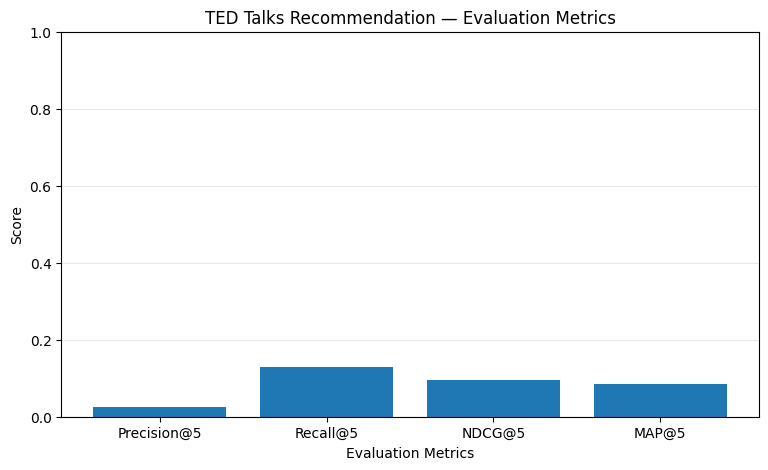

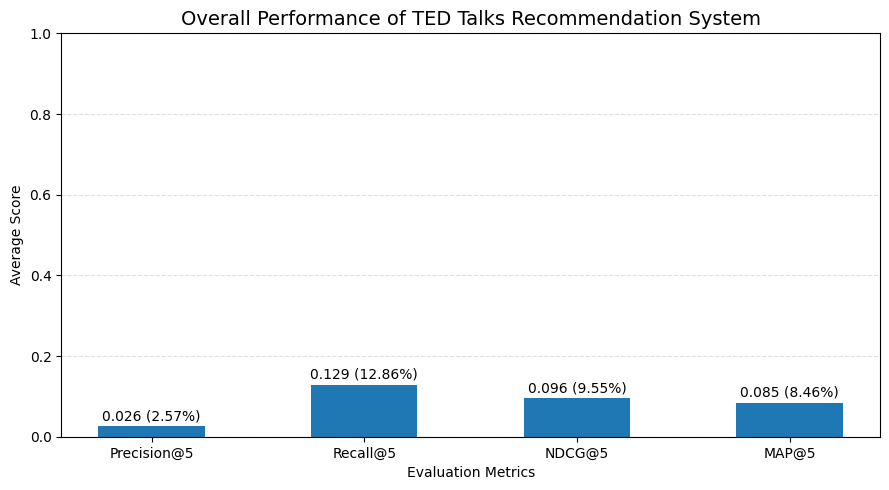

In [ ]:
# MODULE 5: STEP 7 — EVALUATION METRICS VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    evaluation_summary["Metric"],
    evaluation_summary["Score"]
)

plt.title("TED Talks Recommendation — Evaluation Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()


# MODULE 5: STEP 7 — SIMPLE EVALUATION GRAPH

import matplotlib.pyplot as plt

# Calculate average scores
metrics = ["Precision@5", "Recall@5", "NDCG@5", "MAP@5"]

scores = [
    results_df["Precision@5"].mean(),
    results_df["Recall@5"].mean(),
    results_df["NDCG@5"].mean(),
    results_df["AP@5"].mean()
]

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    metrics,
    scores,
    width=0.5
)

# Add score labels above each bar
for bar, score in zip(bars, scores):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{score:.3f} ({score*100:.2f}%)",
        ha="center",
        fontsize=10
    )

plt.title(
    "Overall Performance of TED Talks Recommendation System",
    fontsize=14
)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Average Score")

plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
# MODULE 5: STEP 8 — MODEL COMPARISON

model_comparison = pd.DataFrame([
    {
        "Model": "Content-Based",
        "Method": "TF-IDF + Cosine Similarity",
        "Evaluation Status": "Evaluated",
        "Uses Talk Content": "Yes",
        "Needs User Data": "No"
    },
    {
        "Model": "Collaborative Filtering",
        "Method": "Matrix Factorization",
        "Evaluation Status": "Not implemented",
        "Uses Talk Content": "No",
        "Needs User Data": "Yes"
    },
    {
        "Model": "Hybrid",
        "Method": "Content + Collaborative",
        "Evaluation Status": "Not implemented",
        "Uses Talk Content": "Yes",
        "Needs User Data": "Yes"
    }
])

display(model_comparison)

,Model,Method,Evaluation Status,Uses Talk Content,Needs User Data
0,Content-Based,TF-IDF + Cosine Similarity,Evaluated,Yes,No
1,Collaborative Filtering,Matrix Factorization,Not implemented,No,Yes
2,Hybrid,Content + Collaborative,Not implemented,Yes,Yes


In [ ]:
# MODULE 5: STEP 9 — FINAL MODEL SELECTION

import json

final_model = {
    "selected_model": "Content-Based Recommendation",
    "algorithm": "TF-IDF + Cosine Similarity",
    "reason": (
        "The current dataset contains TED Talk text and metadata "
        "but does not contain genuine user interaction data. "
        "Content-based filtering is therefore the suitable "
        "implemented baseline."
    ),
    "evaluation_metrics": {
        row["Metric"]: float(row["Score"])
        for _, row in evaluation_summary.iterrows()
    }
}

print("FINAL MODEL SELECTION")
print(json.dumps(final_model, indent=4))

FINAL MODEL SELECTION
{
    "selected_model": "Content-Based Recommendation",
    "algorithm": "TF-IDF + Cosine Similarity",
    "reason": "The current dataset contains TED Talk text and metadata but does not contain genuine user interaction data. Content-based filtering is therefore the suitable implemented baseline.",
    "evaluation_metrics": {
        "Precision@5": 0.025725094577553596,
        "Recall@5": 0.12862547288776796,
        "NDCG@5": 0.09553157998246478,
        "MAP@5": 0.08457335014712064
    }
}


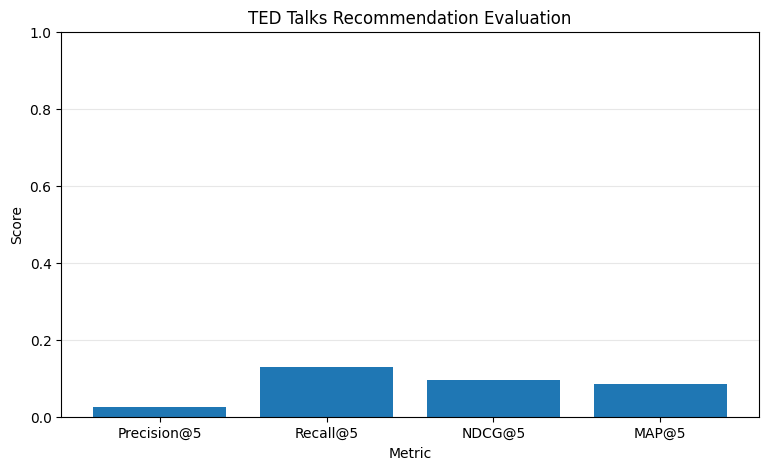

Module 5 evaluation outputs saved!

Saved files:
model_comparison.csv
evaluation_metrics.png
evaluation_results.csv
evaluation_summary.csv
final_model_selection.json


In [ ]:
# MODULE 5: STEP 10 — SAVE EVALUATION OUTPUTS

EVALUATION_DIR = "/content/module5_evaluation_outputs"

os.makedirs(EVALUATION_DIR, exist_ok=True)

# Save individual query results
results_df.to_csv(
    os.path.join(EVALUATION_DIR, "evaluation_results.csv"),
    index=False
)

# Save overall metrics
evaluation_summary.to_csv(
    os.path.join(EVALUATION_DIR, "evaluation_summary.csv"),
    index=False
)

# Save model comparison
model_comparison.to_csv(
    os.path.join(EVALUATION_DIR, "model_comparison.csv"),
    index=False
)

# Save final model selection
with open(
    os.path.join(EVALUATION_DIR, "final_model_selection.json"),
    "w"
) as f:
    json.dump(final_model, f, indent=4)

# Save metric graph
plt.figure(figsize=(9, 5))
plt.bar(
    evaluation_summary["Metric"],
    evaluation_summary["Score"]
)
plt.title("TED Talks Recommendation Evaluation")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.savefig(
    os.path.join(EVALUATION_DIR, "evaluation_metrics.png"),
    bbox_inches="tight"
)
plt.show()

print("Module 5 evaluation outputs saved!")

print("\nSaved files:")
for file in os.listdir(EVALUATION_DIR):
    print(file)

In [ ]:
# MODULE 5: STEP 11 — DOWNLOAD EVALUATION REPORTS

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/module5_evaluation_outputs",
    "zip",
    EVALUATION_DIR
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>